In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split,cross_val_score,RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pickle

Data Loading & Understanding

In [2]:
#read the csv data to a pandas dataframe
df=pd.read_csv("/content/train.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/content/train.csv'

In [ ]:
df.shape

(800, 22)

In [ ]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,0,23.561927,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,0,43.205790,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


In [ ]:
df.tail()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
795,796,0,1,0,0,0,0,0,0,1,1,16.597187,m,Hispanic,no,no,New Zealand,no,12.999501,18 and more,Self,0
796,797,0,1,1,0,0,1,0,1,1,1,20.703001,m,White-European,no,no,Cyprus,no,13.561518,18 and more,Self,0
797,798,0,0,0,0,0,0,0,0,0,0,5.711481,m,South Asian,yes,no,New Zealand,no,2.653177,18 and more,Self,0
798,799,0,0,0,0,0,0,0,0,0,0,16.414305,f,?,no,no,Canada,no,9.069342,18 and more,Self,0
799,800,0,1,0,0,0,0,0,0,0,0,46.966113,f,?,no,no,United Arab Emirates,yes,2.243304,18 and more,Self,0


In [ ]:
#display all columns of a dataframe
pd.set_option('display.max_columns',None)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

In [ ]:
#convert age column to interger
df['age']=df['age'].astype(int)

In [ ]:
df.head(2)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,18 and more,Self,0


In [ ]:
for col in df.columns:
  numerical_features=["ID","age","result"]
  if col not in numerical_features:
    print(col,df[col].unique())
    print("-"*50)

A1_Score [1 0]
--------------------------------------------------
A2_Score [0 1]
--------------------------------------------------
A3_Score [1 0]
--------------------------------------------------
A4_Score [0 1]
--------------------------------------------------
A5_Score [1 0]
--------------------------------------------------
A6_Score [0 1]
--------------------------------------------------
A7_Score [1 0]
--------------------------------------------------
A8_Score [0 1]
--------------------------------------------------
A9_Score [1 0]
--------------------------------------------------
A10_Score [1 0]
--------------------------------------------------
gender ['f' 'm']
--------------------------------------------------
ethnicity ['?' 'White-European' 'Middle Eastern ' 'Pasifika' 'Black' 'Others'
 'Hispanic' 'Asian' 'Turkish' 'South Asian' 'Latino' 'others']
--------------------------------------------------
jaundice ['no' 'yes']
--------------------------------------------------
austim

In [ ]:
#dropping ID & age_desc column
df=df.drop(columns=["ID","age_desc"])

In [ ]:
df.shape

(800, 20)

In [ ]:
df.head(2)

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0


In [ ]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [ ]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Viet Nam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'AmericanSamoa', 'Bahamas', 'Saudi Arabia',
       'Ireland', 'Aruba', 'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan',
       'Armenia', 'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'Hong Kong',
       'Angola', 'China', 'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran',
       'Argentina', 'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone',
       'Czech Republic', 'Niger', 'Romania', 'Cyprus', 'Belgium',
       'Burundi', 'Bangladesh'], dtype=object)

In [ ]:
#define the mapping dictionary for country names
mapping={
    "Viet Nam":"Vietnam",
    "AmericanSamoa":"United States",
    "Hong Kong":"China"
}
df["contry_of_res"]=df["contry_of_res"].replace(mapping)

In [ ]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Vietnam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'Bahamas', 'Saudi Arabia', 'Ireland', 'Aruba',
       'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan', 'Armenia',
       'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'China', 'Angola',
       'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran', 'Argentina',
       'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone', 'Czech Republic',
       'Niger', 'Romania', 'Cyprus', 'Belgium', 'Burundi', 'Bangladesh'],
      dtype=object)

In [ ]:
#target class distribution
df['Class/ASD'].value_counts()

,count
Class/ASD,
0,639
1,161


**Insights**
1. missing values in ethinicity
2. age_desc column has only 1 unique value. so it is removed as it is not important for prediction
3. fixed country names
4. identified class imbalance in the target column


3. Exploratory Data Analysis

In [ ]:
df.shape

(800, 20)

In [ ]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [ ]:
df.head(2)

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0


In [ ]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,27.963750,8.537303,0.201250
std,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.329827,4.807676,0.401185
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,-6.137748,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,5.306575,0.000000
50%,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.000000,9.605299,0.000000
75%,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.250000,12.514484,0.000000
max,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.000000,15.853126,1.000000


Univariable Analysis

Numerical Columns:
 1.  age
 2.  result


In [ ]:
#set the desired theme
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

Distribution Plots

Mean Age: 27.96375
Median Age: 24.0


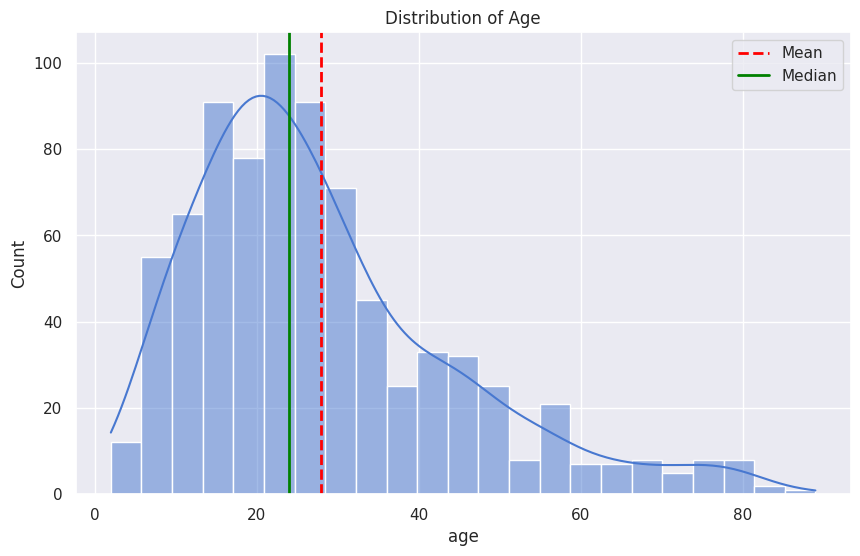

In [ ]:
#Histogram for "Age"
sns.histplot(df['age'], kde=True)
plt.title("Distribution of Age")

#calculate mean and median
mean_age=df['age'].mean()
median_age=df['age'].median()

print("Mean Age:",mean_age)
print("Median Age:",median_age)

#add vertical lines for mean and median
plt.axvline(mean_age, color='red', linestyle='--', linewidth=2, label='Mean')
plt.axvline(median_age, color='green', linestyle='-', linewidth=2, label='Median')

plt.legend()

plt.show()




Mean result: 27.96375
Median result: 24.0


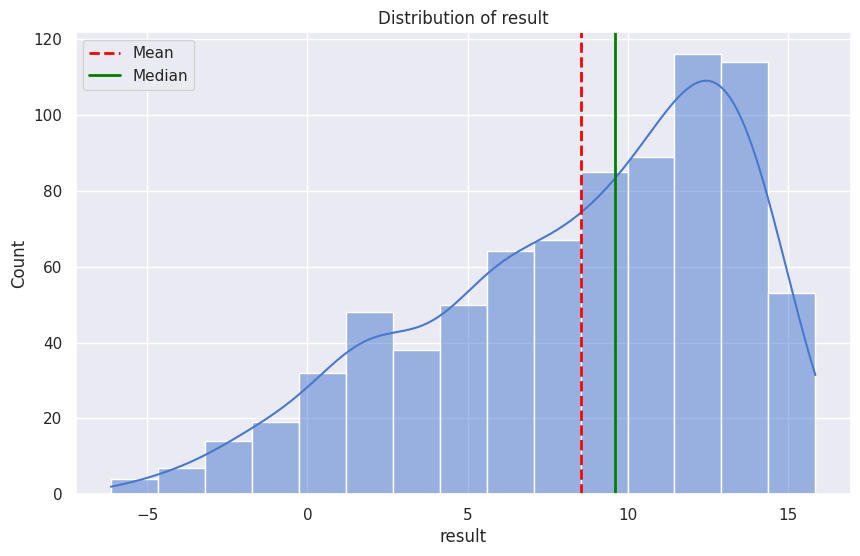

In [ ]:
#Histogram for "result"
sns.histplot(df['result'], kde=True)
plt.title("Distribution of result")

#calculate mean and median
mean_result=df['result'].mean()
median_result=df['result'].median()

print("Mean result:",mean_age)
print("Median result:",median_age)

#add vertical lines for mean and median
plt.axvline(mean_result, color='red', linestyle='--', linewidth=2, label='Mean')
plt.axvline(median_result, color='green', linestyle='-', linewidth=2, label='Median')

plt.legend()

plt.show()

  Box plots for identifying outliers in the numerical columns

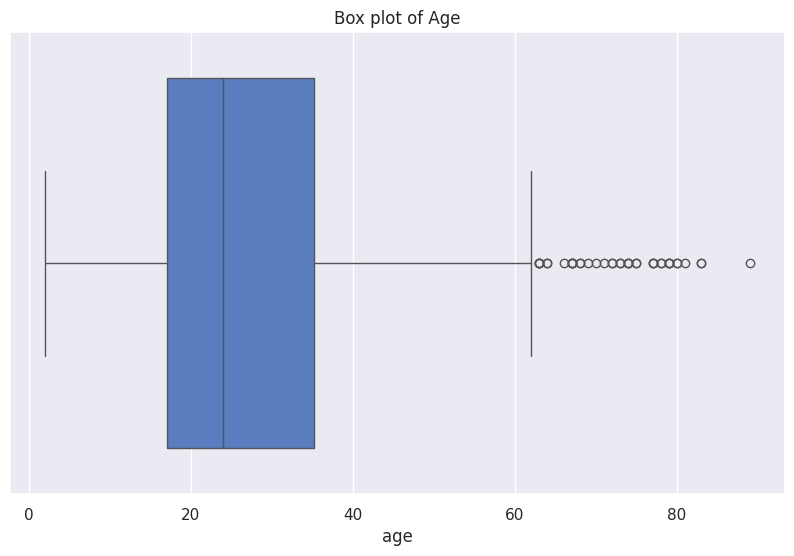

In [ ]:
#box plot
sns.boxplot(x=df['age'])
plt.title("Box plot of Age")
plt.show()

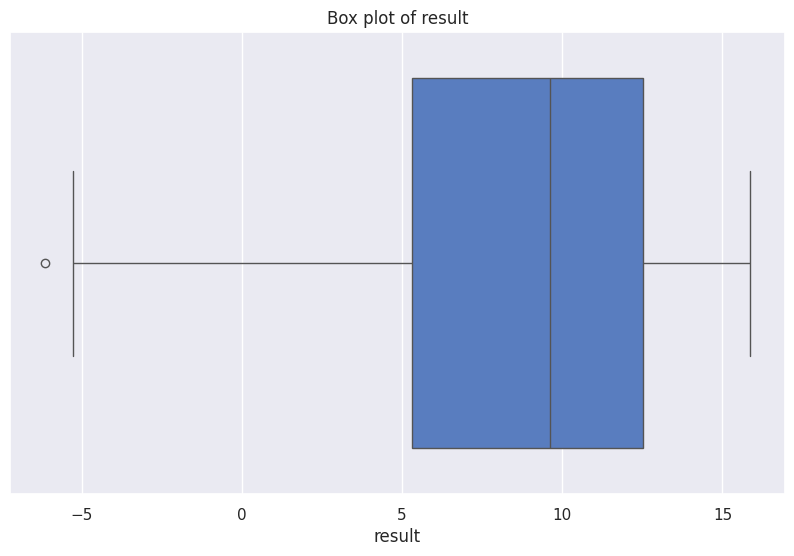

In [ ]:
#box plot
sns.boxplot(x=df['result'])
plt.title("Box plot of result")
plt.show()

In [ ]:
from numpy._core.defchararray import lower
#count the outliers using IQR method
Q1=df['age'].quantile(0.25)
Q3=df['age'].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
age_outliers=df[(df['age']<lower_bound) | (df['age']>upper_bound)]

In [ ]:
print("Number of outliers in age column:",len(age_outliers))

Number of outliers in age column: 39


In [ ]:
 #count the outliers using IQR method
Q1=df['result'].quantile(0.25)
Q3=df['result'].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
result_outliers=df[(df['result']<lower_bound) | (df['result']>upper_bound)]

In [ ]:
print("Number of outliers in result column:",len(result_outliers))

Number of outliers in result column: 1


Univariable analysis of Categorical Columns

In [ ]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

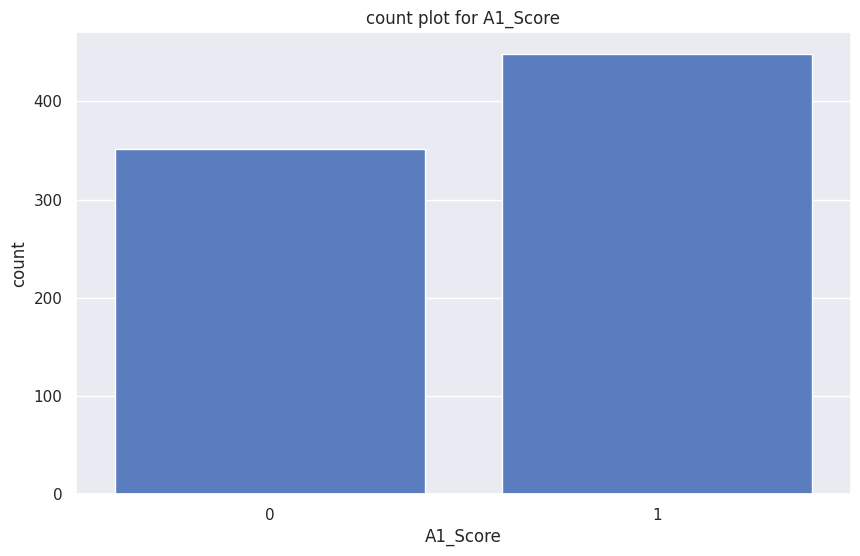

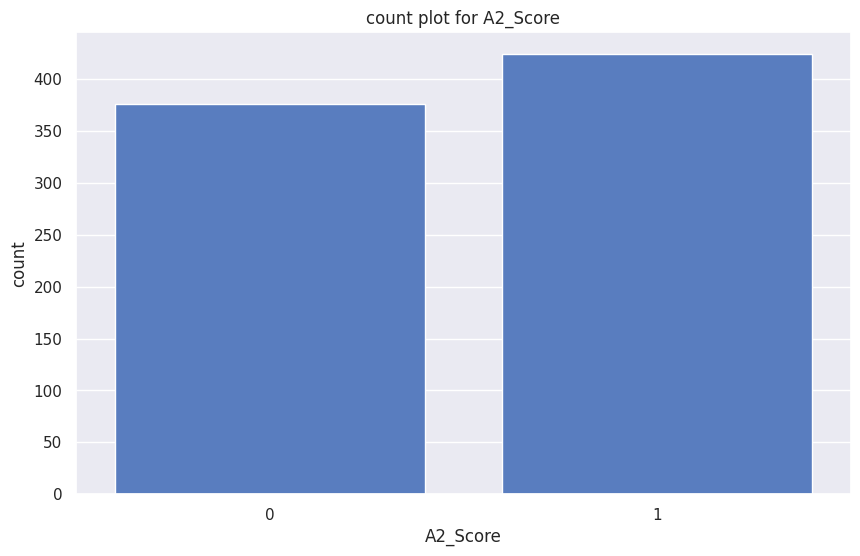

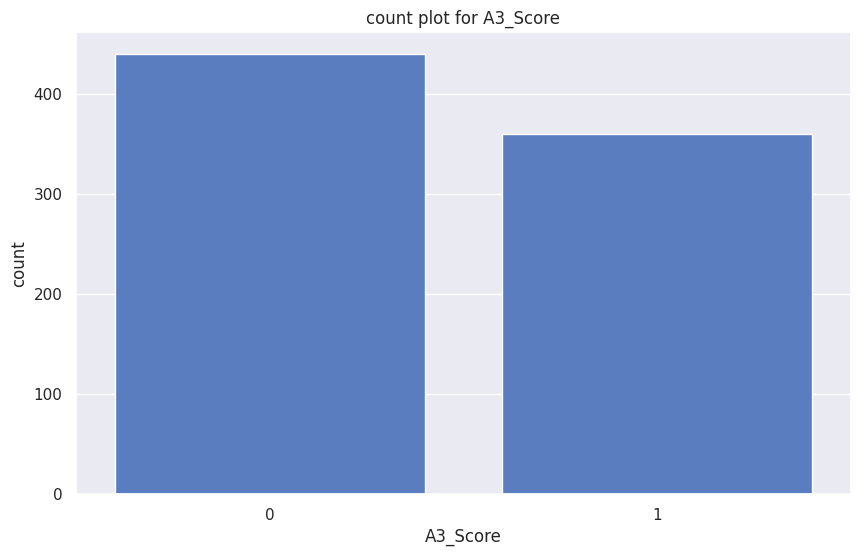

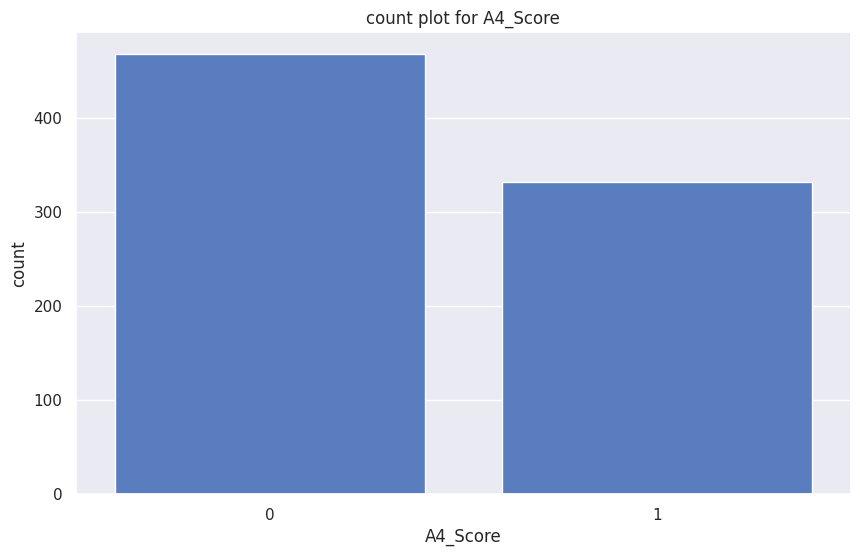

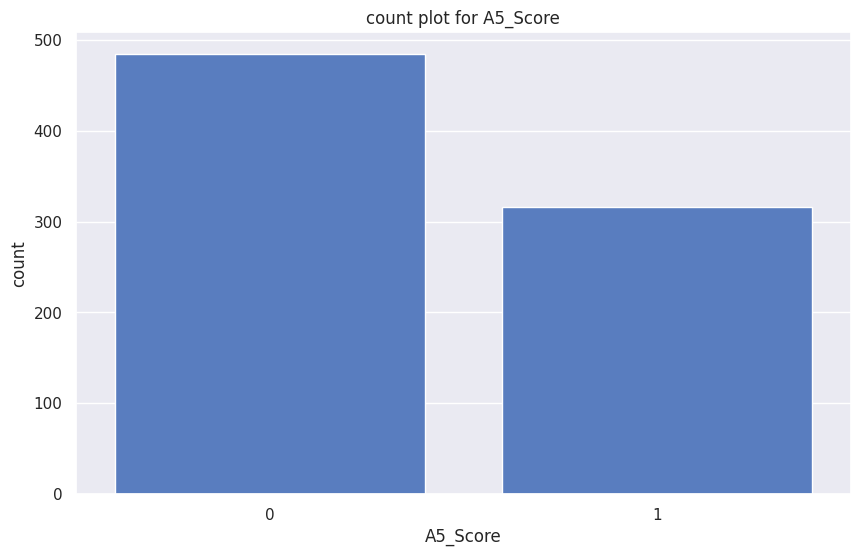

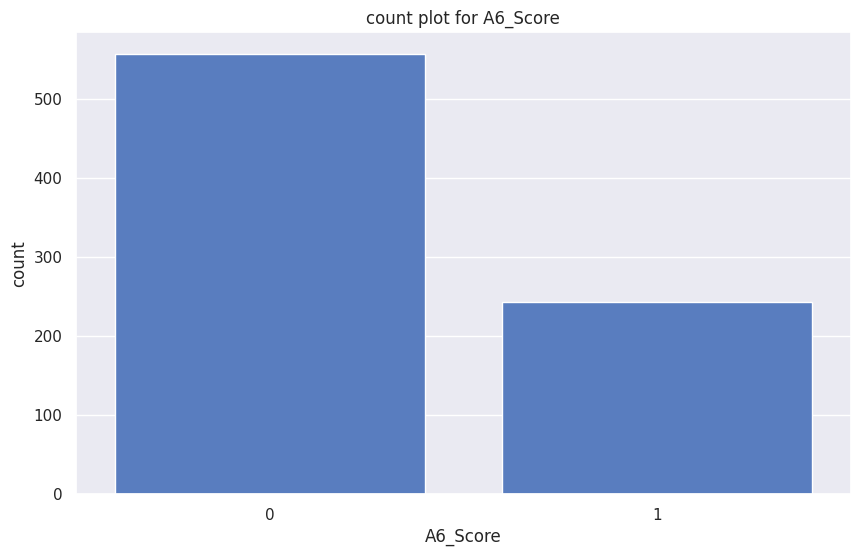

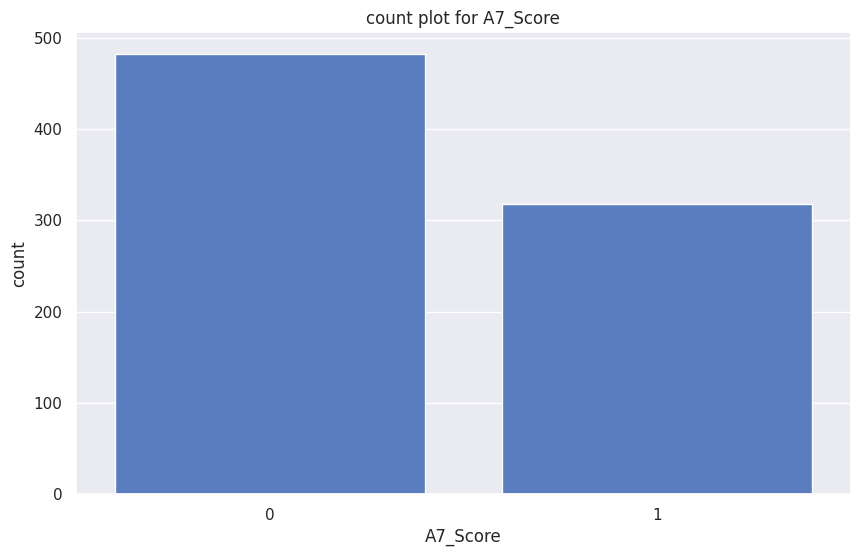

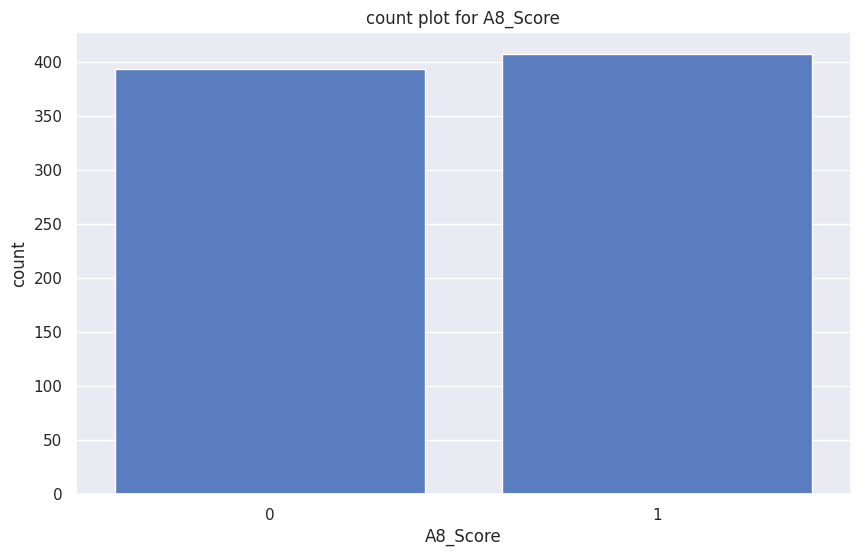

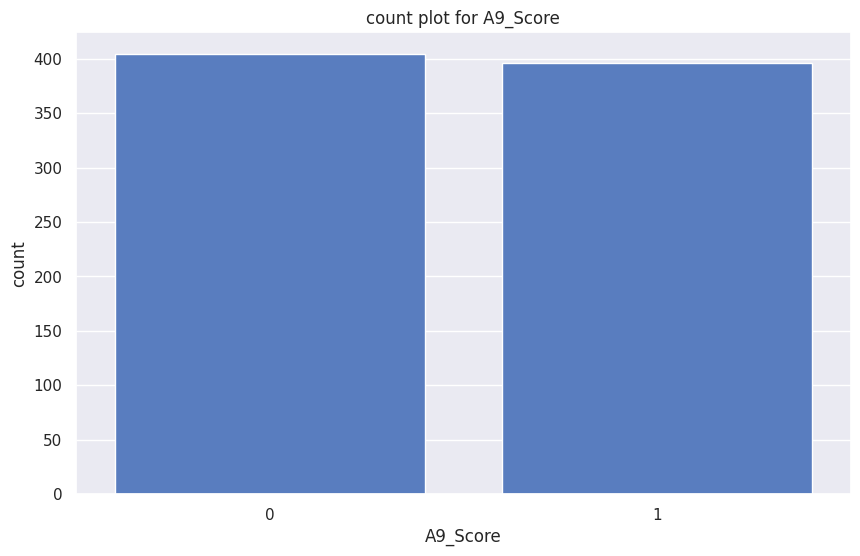

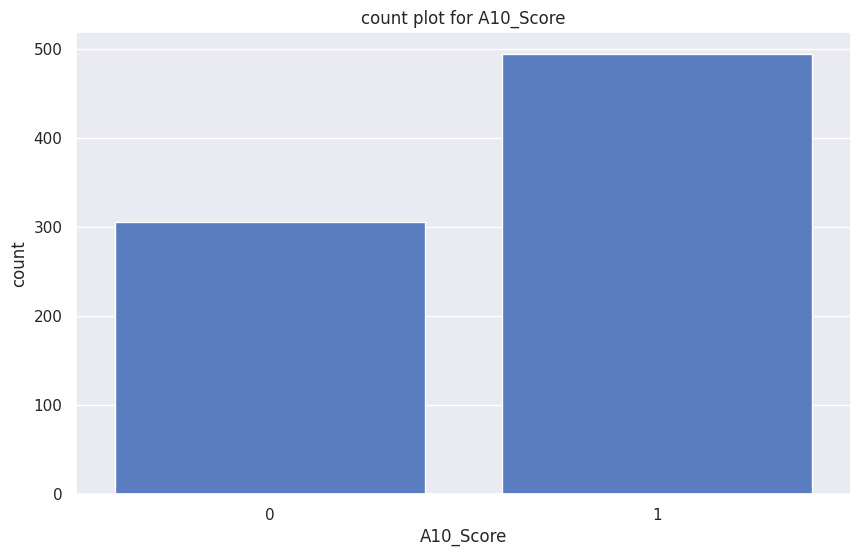

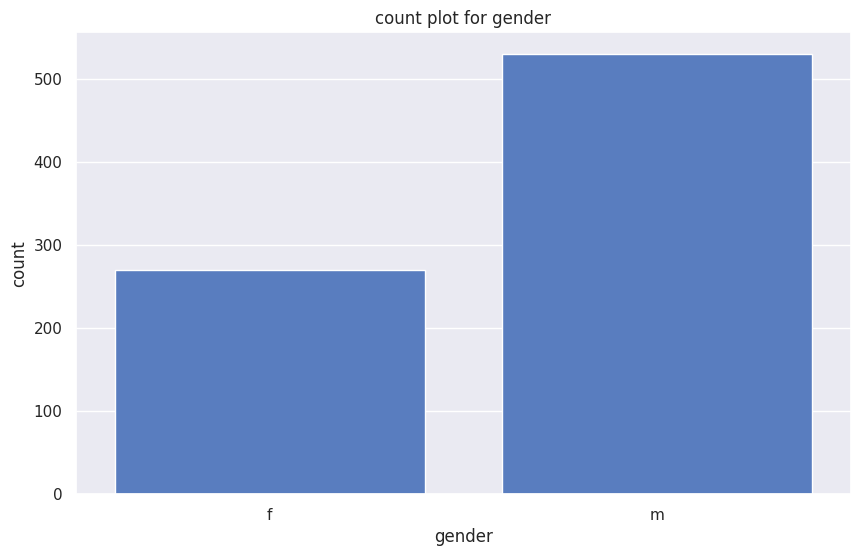

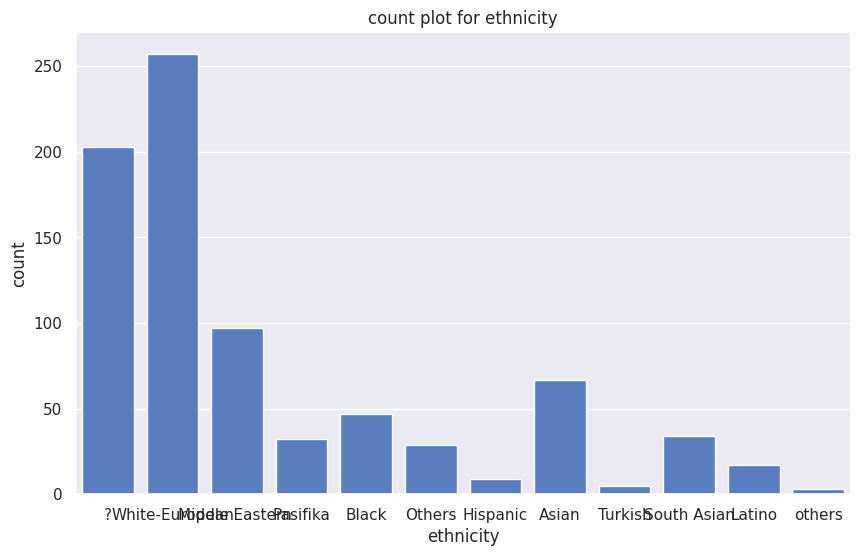

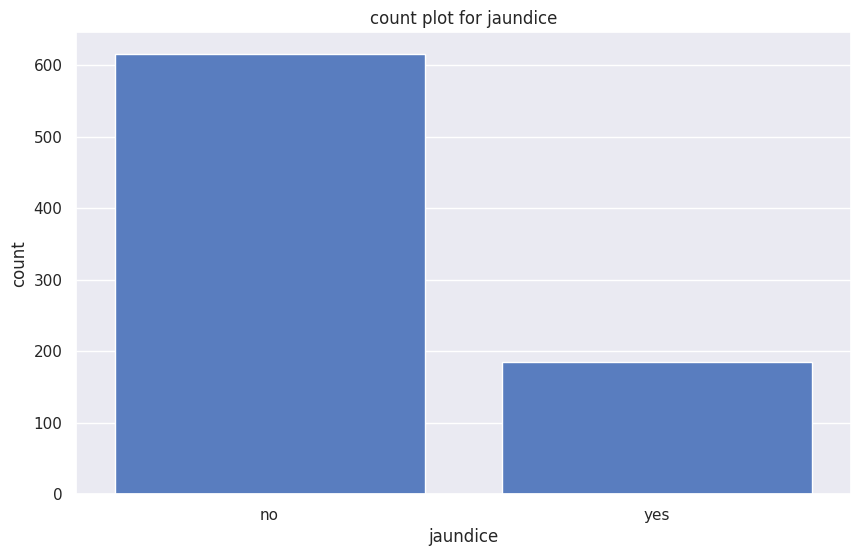

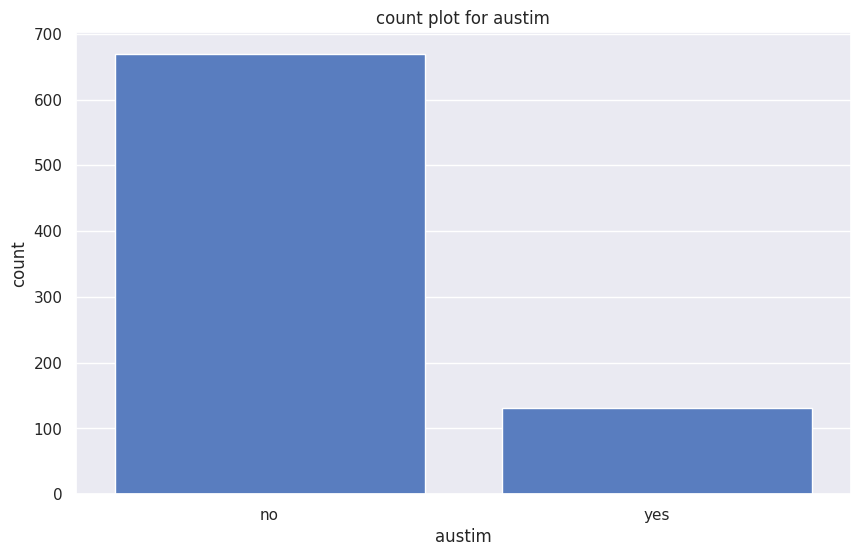

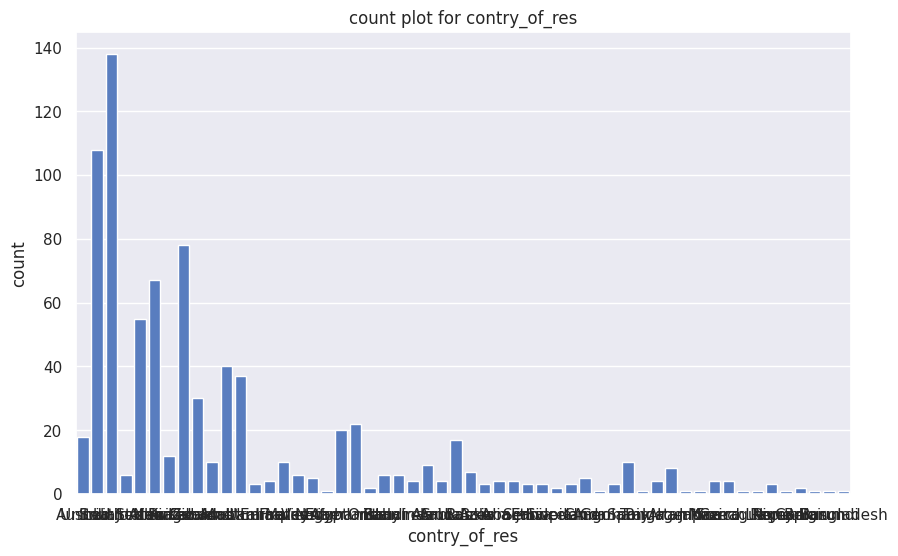

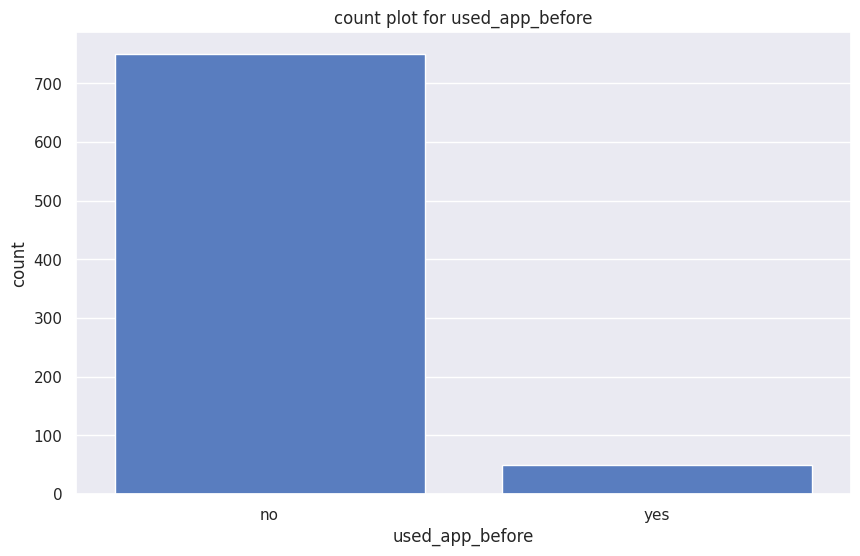

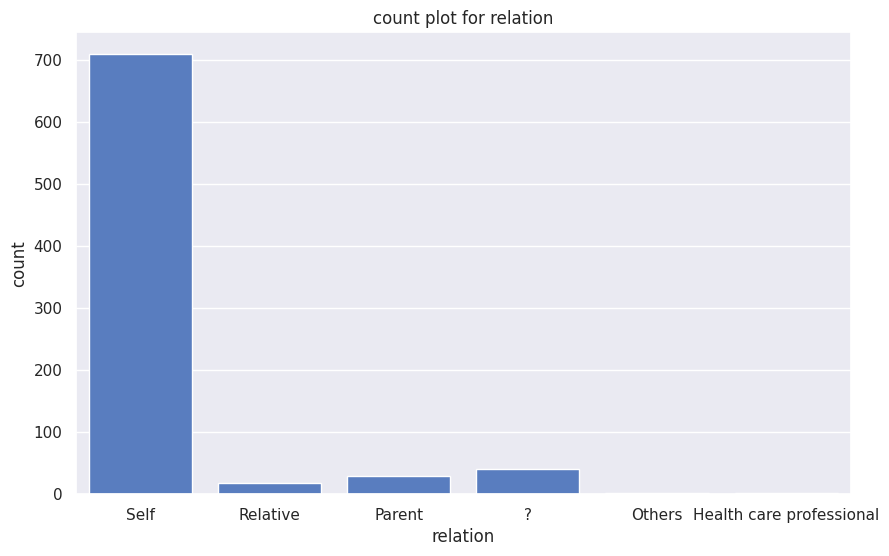

In [ ]:
categorical_columns=['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
        'relation']
for col in categorical_columns :
  sns.countplot(x=df[col])
  plt.title(f"count plot for {col}")
  plt.xlabel(col)
  plt.ylabel('count')
  plt.show()

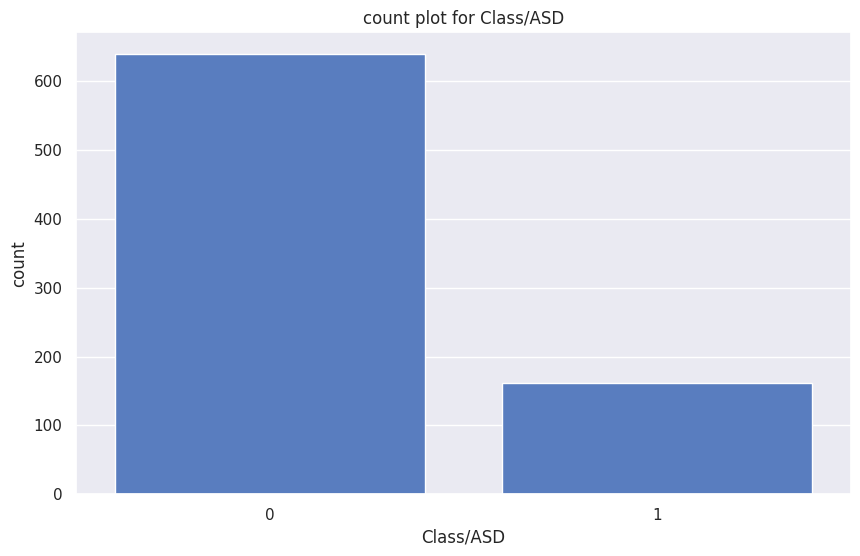

In [ ]:
# countplot for target column
sns.countplot(x=df['Class/ASD'])
plt.title("count plot for Class/ASD")
plt.xlabel('Class/ASD')
plt.ylabel('count')
plt.show()


In [ ]:
df["Class/ASD"].value_counts()

,count
Class/ASD,
0,639
1,161


Handle missing values in ethinicty and relation column

In [ ]:
df['ethnicity']=df['ethnicity'].replace({"?":"Others","others":"Others"})

In [ ]:
df['relation']=df['relation'].replace(
    {
        "?":"Others",
        "other":"Others",
        "others":"Others"


    }


)

In [ ]:
df['relation'].unique()

array(['Self', 'Relative', 'Parent', 'Others', 'Health care professional'],
      dtype=object)

In [ ]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,Others,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,Others,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,Others,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,Others,no,no,South Africa,no,-4.777286,Self,0


Label Encoding

In [ ]:
#identify columns with "object" datatype
object_columns=df.select_dtypes(include=['object']).columns

In [ ]:
print(object_columns)

Index(['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'relation'],
      dtype='object')


In [ ]:
#initialize a dictionary to store the encoders
encoders={}

#apply label encoding and store the encoders
for column in object_columns:
  label_encoder=LabelEncoder()
  df[column]=label_encoder.fit_transform(df[column])
  encoders[column]=label_encoder

  #save the encoders as a pickle file
  with open('label_encoders.pkl','wb') as file:
    pickle.dump(encoders,file)


In [ ]:
encoders

{'gender': LabelEncoder(),
 'ethnicity': LabelEncoder(),
 'jaundice': LabelEncoder(),
 'austim': LabelEncoder(),
 'contry_of_res': LabelEncoder(),
 'used_app_before': LabelEncoder(),
 'relation': LabelEncoder()}

In [ ]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,0,5,0,0,6,0,6.351166,4,0
1,0,0,0,0,0,0,0,0,0,0,47,1,5,0,0,23,0,2.255185,4,0
2,1,1,1,1,1,1,1,1,1,1,7,1,9,0,1,52,0,14.851484,4,1
3,0,0,0,0,0,0,0,0,0,0,23,0,5,0,0,52,0,2.276617,4,0
4,0,0,0,0,0,0,0,0,0,0,43,1,5,0,0,44,0,-4.777286,4,0


Bivariate Analysis

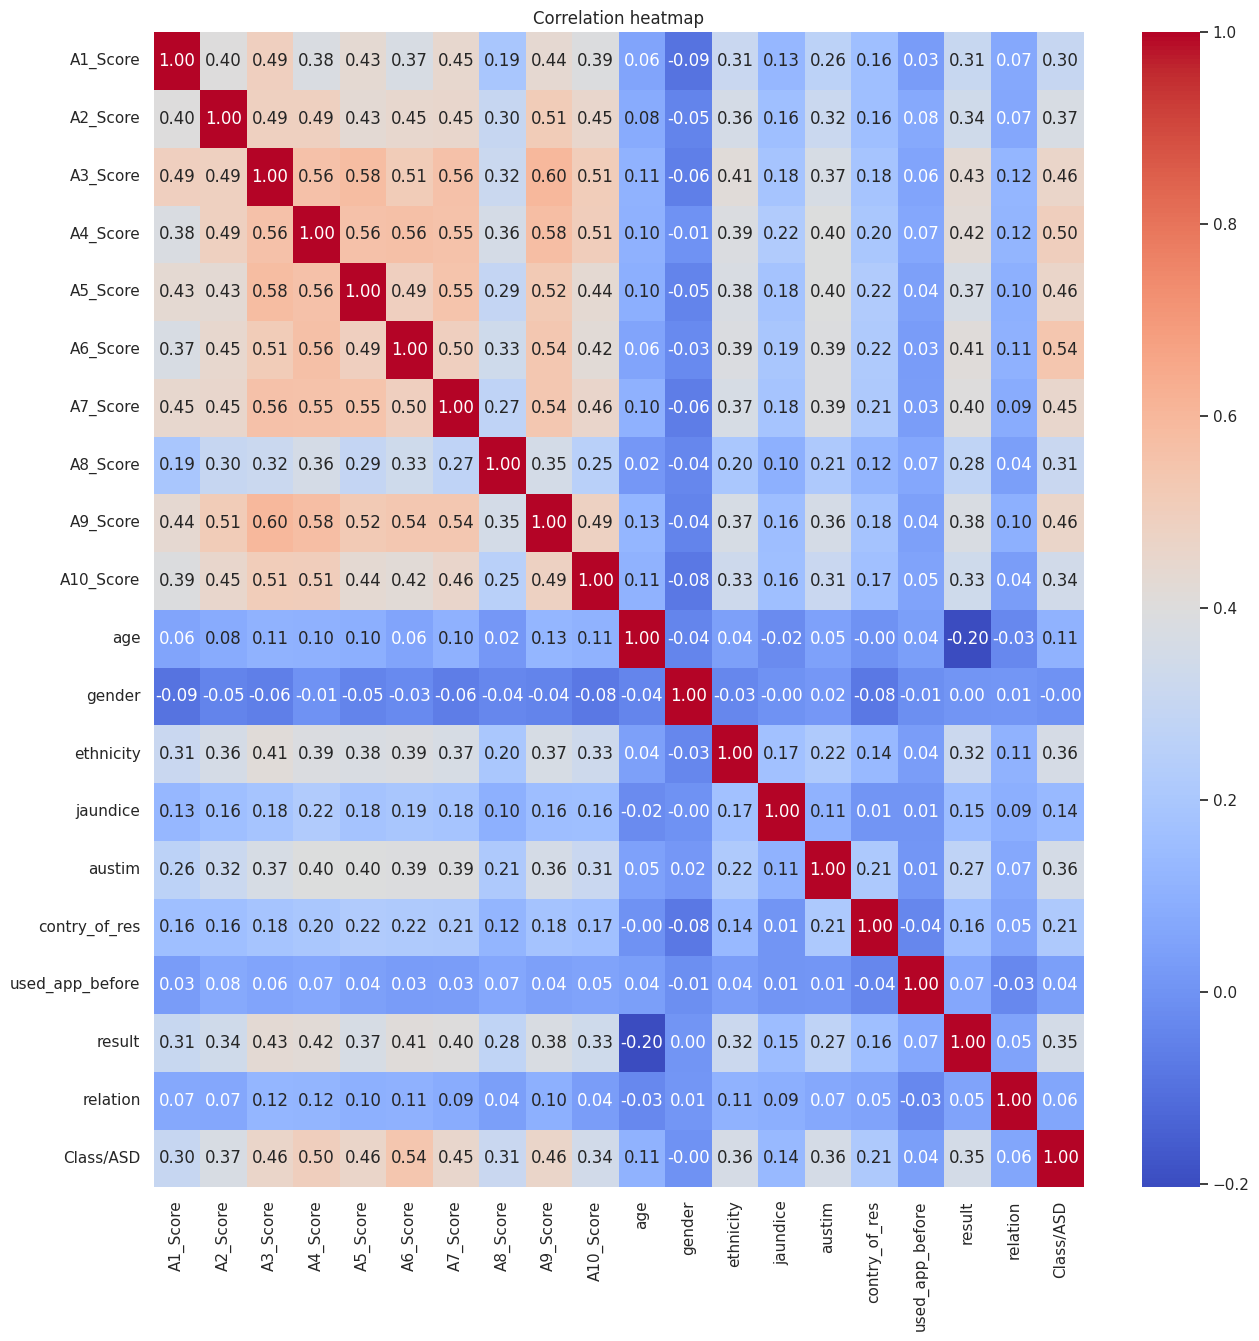

In [ ]:
#correlation matrix
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm',fmt=".2f")
plt.title("Correlation heatmap")
plt.show()



Insights from EDA
- There are few outliers in the numerical columns(age,results)
- There is a class imbalance in the target column
- There is a class imbalance in the categorical features
- we don't have any highly correlated column
- performed label encoding and saved the encoders

4. Data Preprocessing

Handling outliers

In [ ]:
#function to replace the outliers with median
def replace_outliers_with_median(df,column):
  Q1=df[column].quantile(0.25)
  Q3=df[column].quantile(0.75)
  IQR=Q3-Q1

  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  median=df[column].median()

  #replace outliers with median value
  df[column]=df[column].apply(lambda x:median if x<lower_bound or x>upper_bound else x  )
  return df

In [ ]:
#replace outliers in the  "age" column
df=replace_outliers_with_median(df,'age')

#replace outliers in the "result" column
df=replace_outliers_with_median(df,'result')
#

In [ ]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38.0,0,5,0,0,6,0,6.351166,4,0
1,0,0,0,0,0,0,0,0,0,0,47.0,1,5,0,0,23,0,2.255185,4,0
2,1,1,1,1,1,1,1,1,1,1,7.0,1,9,0,1,52,0,14.851484,4,1
3,0,0,0,0,0,0,0,0,0,0,23.0,0,5,0,0,52,0,2.276617,4,0
4,0,0,0,0,0,0,0,0,0,0,43.0,1,5,0,0,44,0,-4.777286,4,0


In [ ]:
df.shape

(800, 20)

Train test split

In [ ]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [ ]:
X=df.drop(columns=['Class/ASD'])
Y=df['Class/ASD']

In [ ]:
print(X)

     A1_Score  A2_Score  A3_Score  A4_Score  A5_Score  A6_Score  A7_Score  \
0           1         0         1         0         1         0         1   
1           0         0         0         0         0         0         0   
2           1         1         1         1         1         1         1   
3           0         0         0         0         0         0         0   
4           0         0         0         0         0         0         0   
..        ...       ...       ...       ...       ...       ...       ...   
795         0         1         0         0         0         0         0   
796         0         1         1         0         0         1         0   
797         0         0         0         0         0         0         0   
798         0         0         0         0         0         0         0   
799         0         1         0         0         0         0         0   

     A8_Score  A9_Score  A10_Score   age  gender  ethnicity  jaundice  aust

In [ ]:
print(Y)

0      0
1      0
2      1
3      0
4      0
      ..
795    0
796    0
797    0
798    0
799    0
Name: Class/ASD, Length: 800, dtype: int64


In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
#

In [ ]:
print(X.shape,X_train.shape,X_test.shape)

(800, 19) (640, 19) (160, 19)


In [ ]:
Y_train.value_counts()

,count
Class/ASD,
0,515
1,125


In [ ]:
Y_test.value_counts()

,count
Class/ASD,
0,124
1,36


SMOTH (synthetic Minority Oversampling technique)

In [ ]:
smoth=SMOTE(random_state=42)
X_train_smoth,Y_train_smoth=smoth.fit_resample(X_train,Y_train)

In [ ]:
print(X_train.shape,X_train_smoth.shape)

(640, 19) (1030, 19)


In [ ]:
print(Y_train.value_counts())
print(Y_train_smoth.value_counts())

Class/ASD
0    515
1    125
Name: count, dtype: int64
Class/ASD
1    515
0    515
Name: count, dtype: int64


5. Model Training

In [ ]:
#list of classifiers
models={
    "Decision Tree":DecisionTreeClassifier(),
    "Random Forest":RandomForestClassifier(),
    "XGBoost":XGBClassifier()
}


In [ ]:
print(models)

{'Decision Tree': DecisionTreeClassifier(), 'Random Forest': RandomForestClassifier(), 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)}


In [ ]:
#dictionary to store the cross validation results
cv_scores={}
#perform 5-fold cross validation for each model
for model_name,model in models.items():
  print(f"Training {model_name} with default parameters...")
  scores=cross_val_score(model,X_train_smoth,Y_train_smoth,cv=5,scoring='accuracy')
  cv_scores[model_name]=scores
  print(f"{model_name} Cross Validation Accuracy: {np.mean(scores):.2f}")
  print("-"*50)

Training Decision Tree with default parameters...
Decision Tree Cross Validation Accuracy: 0.84
--------------------------------------------------
Training Random Forest with default parameters...
Random Forest Cross Validation Accuracy: 0.91
--------------------------------------------------
Training XGBoost with default parameters...
XGBoost Cross Validation Accuracy: 0.90
--------------------------------------------------


In [ ]:
cv_scores

{'Decision Tree': array([0.76699029, 0.84951456, 0.87864078, 0.8592233 , 0.85436893]),
 'Random Forest': array([0.89320388, 0.93203883, 0.90776699, 0.90291262, 0.91262136]),
 'XGBoost': array([0.86893204, 0.9223301 , 0.91262136, 0.90776699, 0.91262136])}

6. Model selection and hyperparamter tuning


In [ ]:
#initializing models
decision_tree=DecisionTreeClassifier(random_state=42)
random_forest=RandomForestClassifier(random_state=42)
xgboost_classifier=XGBClassifier(random_state=42)

In [ ]:
#Hyperparamter grids for RandomizedSearchCV
param_grid_dt={
    'criterion':['gini','entropy'],
    'max_depth':[None,10,20,30,50,70],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4]

}
param_grid_rf={
    'n_estimators':[50,100,200,500],
    'max_depth':[None,10,20,30,50,70],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4],
    'bootstrap':[True,False]
}
param_grid_xgb={
    'n_estimators':[50,100,200,500],
    'learning_rate':[0.01,0.1,0.2,0.3,0.5],
    'max_depth':[3,5,7,10],
    'subsample':[0.5,0.7,0.9,1.0],
    'colsample_bytree':[0.5,0.7,0.9,1.0],
}

In [ ]:
#hyperparamter tuning for 3 tree based models

# the below steps can be automated by using a for loop or by using a pipeline

#perform RandomizedSearchCV for each model
random_search_dt=RandomizedSearchCV(estimator=decision_tree,param_distributions=param_grid_dt,n_iter=10,cv=5,scoring='accuracy',random_state=42)
random_search_rf=RandomizedSearchCV(estimator=random_forest,param_distributions=param_grid_rf,n_iter=10,cv=5,scoring='accuracy',random_state=4)
random_search_xgb=RandomizedSearchCV(estimator=xgboost_classifier,param_distributions=param_grid_xgb,n_iter=10,cv=5,scoring='accuracy',random_state=42)

In [ ]:
# fit the models
random_search_dt.fit(X_train_smoth,Y_train_smoth)
random_search_rf.fit(X_train_smoth,Y_train_smoth)
random_search_xgb.fit(X_train_smoth,Y_train_smoth)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraint...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   param_distributions={'colsample_bytree': [0.5, 0.7, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.1, 0.2, 0.3,
                                                          0.5],
                                        'max_depth': [3, 5, 7, 10],
                                        'n_estimators': [50, 100, 200, 500],
                                        'subsample': [0.5, 0.7, 0.9, 1.0]},
                   random_state=42, scoring='accuracy')

In [ ]:
print("Best parameters for Decision Tree:",random_search_dt.best_params_)
print("Best score for Decision Tree:",random_search_dt.best_score_)

Best parameters for Decision Tree: {'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'entropy'}
Best score for Decision Tree: 0.8601941747572817


In [ ]:
print(random_search_dt.best_estimator_)
print(random_search_rf.best_estimator_)
print(random_search_xgb.best_estimator_)

print(random_search_dt.best_score_)
print(random_search_rf.best_score_)
print(random_search_xgb.best_score_)

DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=2,
                       min_samples_split=5, random_state=42)
RandomForestClassifier(bootstrap=False, max_depth=30, min_samples_split=5,
                       n_estimators=200, random_state=42)
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num

In [ ]:
# Get the model with best score
best_model=None
best_score=0
if random_search_dt.best_score_>best_score:
  best_score=random_search_dt.best_score_
  best_model=random_search_dt.best_estimator_

if random_search_rf.best_score_>best_score:
  best_score=random_search_rf.best_score_
  best_model=random_search_rf.best_estimator_

if random_search_xgb.best_score_>best_score:
  best_score=random_search_xgb.best_score_
  best_model=random_search_xgb.best_estimator_

In [ ]:
print(f"Best model:{best_model}")
print(f"Best cross validation Accuracy:{best_score:.2f}")


Best model:RandomForestClassifier(bootstrap=False, max_depth=30, min_samples_split=5,
                       n_estimators=200, random_state=42)
Best cross validation Accuracy:0.92


In [ ]:
#save the best model
with open('best_model.pkl','wb') as file:
  pickle.dump(best_model,file)

7. Model Evaluation

In [ ]:
#evaluation on test data
y_test_pred=best_model.predict(X_test)
accuracy=accuracy_score(Y_test,y_test_pred)
print("Accuracy on test data:",accuracy)
print("Classification Report",classification_report(Y_test,y_test_pred))

print("Confusion Matrix")
print(confusion_matrix(Y_test,y_test_pred))



Accuracy on test data: 0.825
Classification Report               precision    recall  f1-score   support

           0       0.89      0.88      0.89       124
           1       0.61      0.64      0.62        36

    accuracy                           0.82       160
   macro avg       0.75      0.76      0.75       160
weighted avg       0.83      0.82      0.83       160

Confusion Matrix
[[109  15]
 [ 13  23]]


To do:
1. Build a predictive system with encoders and model file

In [ ]:
def predict_autism(input_data):
    missing_features = set(X.columns) - set(input_data)
    extra_features = set(input_data) - set(X.columns)
    if missing_features or extra_features:
        raise ValueError(f"Input feature mismatch. Missing: {missing_features}; extra: {extra_features}")

    input_frame = pd.DataFrame([input_data], columns=X.columns)
    for column, label_encoder in encoders.items():
        if column in input_frame:
            values = input_frame[column].astype(str)
            unknown_values = set(values) - set(label_encoder.classes_)
            if unknown_values:
                raise ValueError(f"Unknown category for {column}: {unknown_values}")
            input_frame[column] = label_encoder.transform(values)

    prediction = int(best_model.predict(input_frame)[0])
    target_encoder = encoders.get('Class/ASD')
    if target_encoder is not None:
        prediction = target_encoder.inverse_transform([prediction])[0]
    return prediction

sample_input = X.iloc[0].to_dict()
for column, label_encoder in encoders.items():
    if column in sample_input:
        sample_input[column] = label_encoder.inverse_transform([int(sample_input[column])])[0]
print("Sample input:", sample_input)
print("Predicted Class/ASD:", predict_autism(sample_input))